<center><h1>Batra_Raghav_HW7</h1></center>

Name: Raghav Batra
<br>
Github Username: rbatra02
<br>
USC ID: 3227519293

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.exceptions import ConvergenceWarning

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

warnings.filterwarnings("ignore", category=ConvergenceWarning)

DATA_PATH = "../Homework 7 Data/Frogs_MFCCs.csv"
SEED = 42
LABELS = ["Family", "Genus", "Species"]
N_FOLDS = 10

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
df = pd.read_csv(DATA_PATH)
feature_cols = list(df.columns[:22])          # 22 MFCC attr
X = df[feature_cols].to_numpy()
Y = df[LABELS].copy()

print(df.shape)
for lab in LABELS:
    print(f"\n{lab}: {Y[lab].nunique()} classes")
    print(Y[lab].value_counts().to_string())

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, train_size=0.7, random_state=SEED, shuffle=True
)
print("\ntrain:", X_train.shape, " test:", X_test.shape)

(7195, 26)

Family: 4 classes
Family
Leptodactylidae    4420
Hylidae            2165
Dendrobatidae       542
Bufonidae            68

Genus: 8 classes
Genus
Adenomera        4150
Hypsiboas        1593
Ameerega          542
Dendropsophus     310
Leptodactylus     270
Scinax            148
Osteocephalus     114
Rhinella           68

Species: 10 classes
Species
AdenomeraHylaedactylus    3478
HypsiboasCordobae         1121
AdenomeraAndre             672
Ameeregatrivittata         542
HypsiboasCinerascens       472
HylaMinuta                 310
LeptodactylusFuscus        270
ScinaxRuber                148
OsteocephalusOophagus      114
Rhinellagranulosa           68

train: (5036, 22)  test: (2159, 22)


### (b) Train a classifier for each label

#### (i) Research


- **Exact match ratio (subset accuracy):** the fraction of instances whose *entire* label vector is predicted correctly,
  $\frac{1}{n}\sum_i \mathbb{1}[\hat y_i = y_i]$.
- **Hamming loss:** the fraction of individual labels that are wrong,
  $\frac{1}{nL}\sum_i\sum_{l=1}^{L} \mathbb{1}[\hat y_{il} \ne y_{il}]$. Lower is better.
- **Hamming score:** the fraction of individual labels that are right. $1 - \text{Hamming loss}$.

In [3]:
def multilabel_metrics(Y_true, Y_pred):
    wrong = np.asarray(Y_true) != np.asarray(Y_pred)      # n x L boolean
    h_loss = wrong.mean()
    return {
        "exact_match": (~wrong.any(axis=1)).mean(),
        "hamming_loss": h_loss,
        "hamming_score": 1 - h_loss,
    }

results = {}        #metrics on the test set
best_params = {}    #{label: best params}

def fit_binary_relevance(make_search, name, verbose=True):
    #one independently tuned classifier per label.
    preds, params, row = {}, {}, {}
    for lab in LABELS:
        gs = make_search()
        gs.fit(X_train, Y_train[lab])
        preds[lab] = gs.predict(X_test)
        params[lab] = gs.best_params_
        row[f"acc_{lab}"] = (preds[lab] == Y_test[lab].to_numpy()).mean()
        if verbose:
            print(f"[{name}] {lab:8s} best={gs.best_params_}  "
                  f"cv_acc={gs.best_score_:.4f}  test_acc={row[f'acc_{lab}']:.4f}")
    Y_pred = pd.DataFrame(preds)[LABELS]
    row.update(multilabel_metrics(Y_test, Y_pred))
    results[name], best_params[name] = row, params
    if verbose:
        print(f"[{name}] exact match={row['exact_match']:.4f}  "
              f"hamming loss={row['hamming_loss']:.4f}  hamming score={row['hamming_score']:.4f}\n")
    return Y_pred

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

#### (ii) Train a SVM for each of the labels

In [4]:
C_GRID = 10.0 ** np.arange(-1, 5)                      # 0.1 ... 10^4
SIGMA_GRID = np.round(np.arange(0.2, 2.01, 0.2), 2)    # 0.2, 0.4, ..., 2.0
GAMMA_GRID = 1.0 / (2.0 * SIGMA_GRID ** 2)             # gamma = 1 / (2 sigma^2)

def rbf_search():
    pipe = Pipeline([("svm", OneVsRestClassifier(SVC(kernel="rbf")))])
    grid = {"svm__estimator__C": C_GRID, "svm__estimator__gamma": GAMMA_GRID}
    return GridSearchCV(pipe, grid, cv=cv, scoring="accuracy", n_jobs=-1)

pred_rbf_raw = fit_binary_relevance(rbf_search, "RBF SVM (raw)")

for lab, p in best_params["RBF SVM (raw)"].items():
    g = p["svm__estimator__gamma"]
    print(f"{lab:8s} C={p['svm__estimator__C']:g}  sigma={np.sqrt(1/(2*g)):.2f}")

[RBF SVM (raw)] Family   best={'svm__estimator__C': 100.0, 'svm__estimator__gamma': 3.1249999999999996}  cv_acc=0.9927  test_acc=0.9949
[RBF SVM (raw)] Genus    best={'svm__estimator__C': 10.0, 'svm__estimator__gamma': 3.1249999999999996}  cv_acc=0.9919  test_acc=0.9917
[RBF SVM (raw)] Species  best={'svm__estimator__C': 10.0, 'svm__estimator__gamma': 3.1249999999999996}  cv_acc=0.9913  test_acc=0.9907
[RBF SVM (raw)] exact match=0.9893  hamming loss=0.0076  hamming score=0.9924

Family   C=100  sigma=0.40
Genus    C=10  sigma=0.40
Species  C=10  sigma=0.40


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [5]:
C_GRID_L1 = 10.0 ** np.arange(-3, 4)

def l1_svc():
    return LinearSVC(penalty="l1", loss="squared_hinge", dual=False,
                     max_iter=5000, random_state=SEED)

def l1_search():
    pipe = Pipeline([("scale", StandardScaler()), ("svm", l1_svc())])
    return GridSearchCV(pipe, {"svm__C": C_GRID_L1}, cv=cv, scoring="accuracy", n_jobs=-1)

pred_l1 = fit_binary_relevance(l1_search, "L1 linear SVM")

[L1 linear SVM] Family   best={'svm__C': 10.0}  cv_acc=0.9412  test_acc=0.9282


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


[L1 linear SVM] Genus    best={'svm__C': 1000.0}  cv_acc=0.9517  test_acc=0.9416


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increas

[L1 linear SVM] Species  best={'svm__C': 10.0}  cv_acc=0.9607  test_acc=0.9592
[L1 linear SVM] exact match=0.9125  hamming loss=0.0570  hamming score=0.9430



#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [6]:
def l1_smote_search():
    pipe = ImbPipeline([("scale", StandardScaler()),
                        ("smote", SMOTE(random_state=SEED)),
                        ("svm", l1_svc())])
    return GridSearchCV(pipe, {"svm__C": C_GRID_L1}, cv=cv, scoring="accuracy", n_jobs=-1)

pred_l1_smote = fit_binary_relevance(l1_smote_search, "L1 linear SVM + SMOTE")

summary = pd.DataFrame(results).T[
    ["acc_Family", "acc_Genus", "acc_Species", "exact_match", "hamming_loss", "hamming_score"]
]
display(summary.round(4))

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


[L1 linear SVM + SMOTE] Family   best={'svm__C': 10.0}  cv_acc=0.9232  test_acc=0.9092
[L1 linear SVM + SMOTE] Genus    best={'svm__C': 1.0}  cv_acc=0.9128  test_acc=0.9023


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increas

[L1 linear SVM + SMOTE] Species  best={'svm__C': 10.0}  cv_acc=0.9581  test_acc=0.9579
[L1 linear SVM + SMOTE] exact match=0.8536  hamming loss=0.0769  hamming score=0.9231



,acc_Family,acc_Genus,acc_Species,exact_match,hamming_loss,hamming_score
RBF SVM (raw),0.9949,0.9917,0.9907,0.9893,0.0076,0.9924
L1 linear SVM,0.9282,0.9416,0.9592,0.9125,0.0570,0.9430
L1 linear SVM + SMOTE,0.9092,0.9023,0.9579,0.8536,0.0769,0.9231


In [7]:
from sklearn.metrics import recall_score
rows = []
for lab in LABELS:
    classes = sorted(Y[lab].unique())
    for name, pred in [("L1", pred_l1), ("L1 + SMOTE", pred_l1_smote), ("RBF (raw)", pred_rbf_raw)]:
        rec = recall_score(Y_test[lab], pred[lab], labels=classes, average=None, zero_division=0)
        for c, r in zip(classes, rec):
            rows.append({"label": lab, "class": c, "n_test": int((Y_test[lab] == c).sum()),
                         "method": name, "recall": r})
pd.DataFrame(rows).pivot_table(index=["label", "class", "n_test"], columns="method", values="recall").round(3)

method                                    L1  L1 + SMOTE  RBF (raw)
label   class                  n_test                              
Family  Bufonidae              27      0.000       0.889      0.926
        Dendrobatidae          162     0.895       0.975      0.994
        Hylidae                623     0.904       0.867      0.998
        Leptodactylidae        1347    0.962       0.921      0.995
Genus   Adenomera              1251    0.978       0.890      0.997
        Ameerega               162     0.932       0.957      1.000
        Dendropsophus          84      0.714       0.893      0.964
        Hypsiboas              468     0.970       0.912      0.998
        Leptodactylus          96      0.906       0.896      0.979
        Osteocephalus          34      0.500       0.882      0.882
        Rhinella               27      0.259       0.926      0.926
        Scinax                 37      0.892       0.973      0.946
Species AdenomeraAndre         220     0.914       0.877      0.982
        AdenomeraHylaedactylus 1031    0.999       0.994      1.000
        Ameeregatrivittata     162     0.944       0.944      1.000
        HylaMinuta             84      0.774       0.893      0.964
        HypsiboasCinerascens   135     0.963       0.963      0.978
        HypsiboasCordobae      333     0.976       0.946      0.997
        LeptodactylusFuscus    96      0.896       0.906      0.979
        OsteocephalusOophagus  34      0.647       0.882      0.882
        Rhinellagranulosa      27      0.889       0.926      0.926
        ScinaxRuber            37      0.946       0.946      0.973

The Gaussian-kernel SVMs were best as exact match 0.989, Hamming loss 0.008, with recall of at least 0.88 on every class. The L1-penalized linear SVMs were worse (0.913, 0.057) and failed on the rare classes with recall 0 for Bufonidae and 0.259 for Rhinella. SMOTE fixed most of it a fair amount with Bufonidae 0.889, Rhinella 0.926, but lowered recall on the large classes, so overall performance fell to 0.854 exact match, 0.077 hamming loss. SMOTE therefore trades overall accuracy for minority-class recall, which is only good if the rare classes matter more than aggregate accuracy. The classes are not well separated by linear one-vs-rest boundaries, and the Gaussian kernel handles both the non-linearity and the imbalance without resampling.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [8]:
N_MC = 50
K_VALUES = range(2, 51)
Y_all = Y[LABELS].to_numpy()

def choose_k(seed):
    # (a) run k-means for every k and keep the k with largest sil
    best = (-np.inf, None, None)
    for k in K_VALUES:
        km = KMeans(n_clusters=k, n_init=5, random_state=seed).fit(X)
        s = silhouette_score(X, km.labels_)
        if s > best[0]:
            best = (s, k, km.labels_)
    return best          # (sil, k, cluster of each point)

sil, k, clusters = choose_k(seed=1)
print(f"run 1: chosen k = {k}, silhouette = {sil:.4f}")

run 1: chosen k = 4, silhouette = 0.3787


### (b) Determine which family is the majority

In [9]:
def majority_labels(clusters):
    lab_df = Y[LABELS].assign(cluster=clusters)
    return lab_df.groupby("cluster")[LABELS].agg(lambda s: s.value_counts().idxmax())

majority = majority_labels(clusters)
majority

,Family,Genus,Species
cluster,,,
0,Hylidae,Hypsiboas,HypsiboasCinerascens
1,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
2,Hylidae,Hypsiboas,HypsiboasCordobae
3,Dendrobatidae,Ameerega,Ameeregatrivittata


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [10]:
def hamming_metrics(clusters, majority):
    # (c) cluster's majority triplet and compare with the truth
    Y_hat = majority.loc[clusters].to_numpy()
    wrong = Y_hat != Y_all
    h_loss = wrong.mean()
    return {"hamming_distance": wrong.sum(axis=1).mean(),
            "hamming_loss": h_loss,
            "hamming_score": 1 - h_loss}

In [11]:
def one_run(seed):
    sil, k, clusters = choose_k(seed)
    majority = majority_labels(clusters)
    return {"seed": seed, "k": k, "silhouette": sil,
            **hamming_metrics(clusters, majority), "majority": majority}

runs = Parallel(n_jobs=-1)(delayed(one_run)(s) for s in range(1, N_MC + 1))
mc = pd.DataFrame([{k: v for k, v in r.items() if k != "majority"} for r in runs])

print("Chosen k across the runs:")
print(mc["k"].value_counts().sort_index().to_string())
mc[["hamming_distance", "hamming_loss", "hamming_score"]].agg(["mean", "std"]).T.round(4)

Chosen k across the runs:
k
4    50


,mean,std
hamming_distance,0.6862,0.0389
hamming_loss,0.2287,0.0130
hamming_score,0.7713,0.0130


## 3. ISLR 12.6.2

Dissimilarity matrix for four observations:

$$\begin{pmatrix} & 0.3 & 0.4 & 0.7\\ 0.3 & & 0.5 & 0.8\\ 0.4 & 0.5 & & 0.45\\ 0.7 & 0.8 & 0.45 & \end{pmatrix}$$

**(a) Complete linkage.**
1. Smallest dissimilarity is $d(1,2)=0.3$, so 1 and 2 fuse at height **0.3**.
2. Updated dissimilarities: $d(\{1,2\},3)=\max(0.4,0.5)=0.5$, $d(\{1,2\},4)=\max(0.7,0.8)=0.8$, $d(3,4)=0.45$. The smallest is 0.45, so 3 and 4 fuse at height **0.45**.
3. $d(\{1,2\},\{3,4\})=\max(0.4,0.7,0.5,0.8)=0.8$, so the two clusters fuse at height **0.8**.

**(b) Single linkage.**
1. 1 and 2 fuse at height **0.3**.
2. $d(\{1,2\},3)=\min(0.4,0.5)=0.4$, $d(\{1,2\},4)=\min(0.7,0.8)=0.7$, $d(3,4)=0.45$. The smallest is 0.4, so 3 joins $\{1,2\}$ at height **0.4**.
3. $d(\{1,2,3\},4)=\min(0.7,0.8,0.45)=0.45$, so 4 joins at height **0.45**.

**(c)** Cutting the complete-linkage dendrogram into two clusters (any height between 0.45 and 0.8) gives $\{1,2\}$ and $\{3,4\}$.

**(d)** Cutting the single-linkage dendrogram into two clusters (any height between 0.4 and 0.45) gives $\{1,2,3\}$ and $\{4\}$.

**(e)** Mirror the two branches gives the leaf order 3, 4, 1, 2 with dendrogram below

complete linkage fusion heights: [0.3  0.45 0.8 ]
single linkage fusion heights:   [0.3  0.4  0.45]


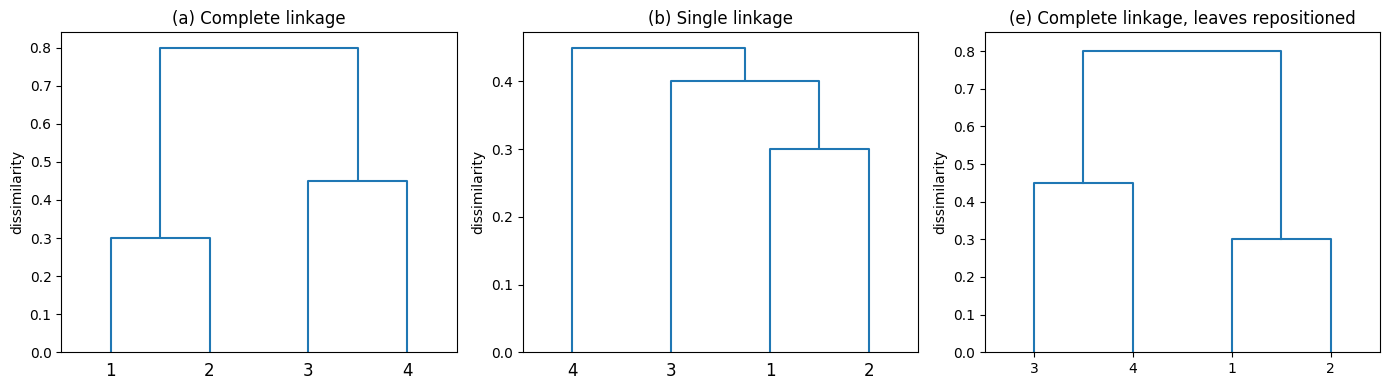

In [12]:
D = np.array([[0.0, 0.3, 0.4, 0.7],
              [0.3, 0.0, 0.5, 0.8],
              [0.4, 0.5, 0.0, 0.45],
              [0.7, 0.8, 0.45, 0.0]])
d = squareform(D)
obs = ["1", "2", "3", "4"]

Z_complete = linkage(d, method="complete")
Z_single = linkage(d, method="single")
print("complete linkage fusion heights:", Z_complete[:, 2])
print("single linkage fusion heights:  ", Z_single[:, 2])

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
dendrogram(Z_complete, labels=obs, ax=axes[0], color_threshold=0)
axes[0].set_title("(a) Complete linkage")
dendrogram(Z_single, labels=obs, ax=axes[1], color_threshold=0)
axes[1].set_title("(b) Single linkage")

# (e) same complete-linkage tree with the two branches mirrored: leaf order 3, 4, 1, 2
ax = axes[2]
for xs, ys in [([0, 0, 1, 1], [0, 0.45, 0.45, 0]),          # 3-4 at 0.45
               ([2, 2, 3, 3], [0, 0.3, 0.3, 0]),            # 1-2 at 0.3
               ([0.5, 0.5, 2.5, 2.5], [0.45, 0.8, 0.8, 0.3])]:
    ax.plot(xs, ys, color="C0")
ax.set_xticks(range(4)); ax.set_xticklabels(["3", "4", "1", "2"])
ax.set_ylim(0, 0.85); ax.set_xlim(-0.5, 3.5)
ax.set_title("(e) Complete linkage, leaves repositioned")
for a in axes:
    a.set_ylabel("dissimilarity")
plt.tight_layout(); plt.show()